# 04 — Feature Engineering
**Part C | Milestone 4**

Question: can we turn each 1-second IMU window (200×6 raw samples) into a compact row of numbers that predicts drift? This notebook **calls** the extraction code in `src/vio_drift/features/` (no logic is re-implemented here) and then analyses the result: correlation with the label, RandomForest importance, redundancy, and a feature-selection experiment.

The feature tables themselves are written by `python scripts/make_features.py` into `data/processed/features_<seq>.csv`. Figures are saved to `figures/ml/` with a `feature_` prefix.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

from vio_drift.features.build_features import (
    build_sequence, feature_names, fit_scaler, apply_scaler,
)
from vio_drift.features import time_domain, frequency_domain, cross_axis

ROOT = Path.cwd().parent
FIG = ROOT / "figures" / "ml"
FIG.mkdir(parents=True, exist_ok=True)

config = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())
sequences = config["data"]["sequences"]
processed = ROOT / config["data"]["processed_dir"]
fs = float(config["windowing"]["imu_rate_hz"])
seed = int(config["seed"])

FEATS = feature_names()
print(f"{len(FEATS)} features = "
      f"{len(time_domain.feature_names())} time-domain + "
      f"{len(frequency_domain.feature_names())} frequency + "
      f"{len(cross_axis.feature_names())} cross-axis")

104 features = 60 time-domain + 18 frequency + 26 cross-axis


## 1. Load the feature tables

We read the handoff files written by `make_features.py`. If they are missing we build them on the fly from Part A's `windows_raw_<seq>.npy`, so this notebook runs standalone.

In [2]:
frames = {}
for seq in sequences:
    f = processed / f"features_{seq}.csv"
    if f.exists():
        frames[seq] = pd.read_csv(f)
    else:
        frames[seq] = build_sequence(
            seq, processed / f"windows_raw_{seq}.npy",
            processed / f"windows_{seq}.csv", fs=fs)
    print(seq, frames[seq].shape, "NaNs:", int(frames[seq].isna().sum().sum()))

pooled = pd.concat(frames.values(), ignore_index=True)
print("pooled:", pooled.shape)
pooled.head(3)

MH_01_easy (724, 107) NaNs: 0
MH_02_easy (596, 107) NaNs: 0
MH_03_medium (523, 107) NaNs: 0
pooled: (1843, 107)


,seq_id,window_id,gx_mean,gx_std,gx_var,gx_rms,gx_min,gx_max,gx_ptp,gx_skew,...,corr_gy_ax,corr_gy_ay,corr_gy_az,corr_gz_ax,corr_gz_ay,corr_gz_az,corr_ax_ay,corr_ax_az,corr_ay_az,err_mag_m
0,MH_01_easy,0,-0.025991,0.083757,0.007015,0.087697,-0.255516,0.157778,0.413294,-0.666033,...,0.108469,-0.065532,-0.460306,0.188182,0.235974,0.013723,-0.062042,-0.856492,0.159843,0.139936
1,MH_01_easy,1,-0.009547,0.064226,0.004125,0.064931,-0.136136,0.157778,0.293913,0.465144,...,-0.483649,0.186114,0.237430,0.427992,0.083853,-0.364114,-0.219713,-0.901066,0.253612,0.152153
2,MH_01_easy,2,0.005585,0.068098,0.004637,0.068327,-0.136136,0.157778,0.293913,-0.070267,...,-0.408493,0.184281,0.316802,0.294057,0.061256,-0.164635,-0.313038,-0.963998,0.372520,0.171830


## 2. Family breakdown

A quick count that each feature family contributes the expected number of columns, and that the handoff column contract holds: `seq_id, window_id, <features...>, err_mag_m`.

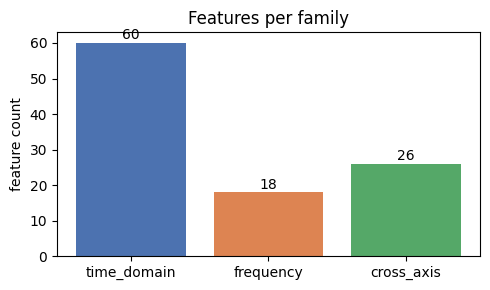

In [3]:
assert list(pooled.columns[:2]) == ["seq_id", "window_id"]
assert pooled.columns[-1] == "err_mag_m"
assert list(pooled.columns[2:-1]) == FEATS
counts = {
    "time_domain": len(time_domain.feature_names()),
    "frequency":   len(frequency_domain.feature_names()),
    "cross_axis":  len(cross_axis.feature_names()),
}
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.keys(), counts.values(), color=["#4C72B0", "#DD8452", "#55A868"])
for i, v in enumerate(counts.values()):
    ax.text(i, v + 1, str(v), ha="center")
ax.set_ylabel("feature count"); ax.set_title("Features per family")
fig.tight_layout(); fig.savefig(FIG / "feature_family_counts.png", dpi=150); plt.show()

## 3. Correlation with the label

Pearson correlation of each feature with `err_mag_m`, pooled across the three sequences. This is a first, linear look at which features carry signal — tree models can still use the rest non-linearly.

ax_mean            0.473
ax_rms             0.463
az_spec_entropy    0.369
az_rms            -0.343
az_mean            0.341
ax_spec_entropy    0.325
az_max             0.310
ay_spec_entropy    0.308
az_zcr             0.302
ay_zcr             0.298
ax_zcr             0.279
acc_mag_mean       0.278
jerk_az_rms        0.242
jerk_mag_mean      0.240
jerk_ax_rms        0.235
corr_ax_az        -0.234
jerk_ay_rms        0.230
jerk_mag_max       0.205
gz_zcr             0.204
gx_zcr             0.201


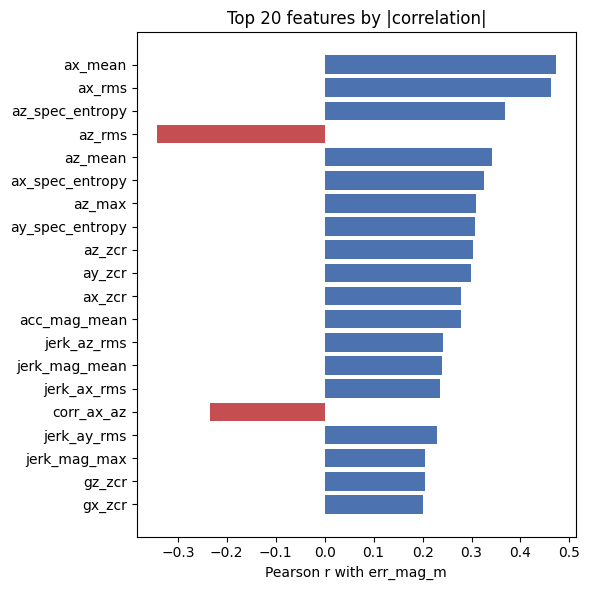

In [4]:
corr = pooled[FEATS + ["err_mag_m"]].corr()["err_mag_m"].drop("err_mag_m")
top = corr.abs().sort_values(ascending=False).head(20)
print(corr.reindex(top.index).round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 6))
vals = corr.reindex(top.index[::-1])
ax.barh(vals.index, vals.values,
        color=["#C44E52" if v < 0 else "#4C72B0" for v in vals.values])
ax.set_xlabel("Pearson r with err_mag_m"); ax.set_title("Top 20 features by |correlation|")
fig.tight_layout(); fig.savefig(FIG / "feature_correlation_top20.png", dpi=150); plt.show()

## 4. RandomForest feature importance

A non-linear view. We fit a quick RandomForest on the pooled data (impurity importance). This is a ranking aid for feature selection, **not** a performance result — honest, fold-respecting metrics are Part D's job (train/test by sequence, scaler fit on train only).

ax_rms          0.1765
ax_mean         0.0817
ay_mean         0.0737
corr_gz_ax      0.0206
acc_mag_mean    0.0197
gy_mean         0.0182
ay_rms          0.0157
gx_mean         0.0147
gz_mean         0.0135
gx_max          0.0129
corr_gy_ax      0.0129
az_max          0.0129
gx_kurt         0.0126
az_mean         0.0124
az_rms          0.0121
gz_max          0.0118
ax_skew         0.0117
ax_zcr          0.0115
gz_min          0.0109
ax_min          0.0102


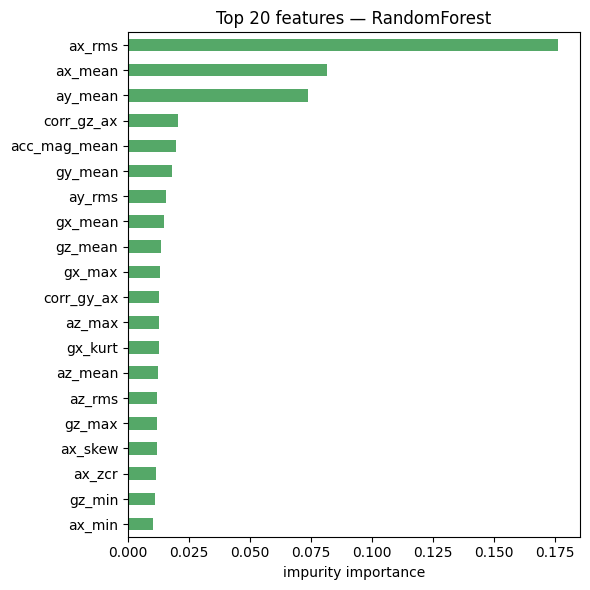

In [5]:
rf = RandomForestRegressor(n_estimators=300, random_state=seed, n_jobs=-1)
rf.fit(pooled[FEATS], pooled["err_mag_m"])
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values(ascending=False)
print(imp.head(20).round(4).to_string())

fig, ax = plt.subplots(figsize=(6, 6))
imp.head(20)[::-1].plot.barh(ax=ax, color="#55A868")
ax.set_xlabel("impurity importance"); ax.set_title("Top 20 features — RandomForest")
fig.tight_layout(); fig.savefig(FIG / "feature_importance_rf.png", dpi=150); plt.show()

## 5. Redundancy

Many features are collinear by construction (variance = std²; RMS ≈ |mean| when the mean dominates). We count highly-correlated feature pairs and show the correlation heatmap for the top importance features, to motivate feature selection.

feature pairs with |corr| > 0.95: 17


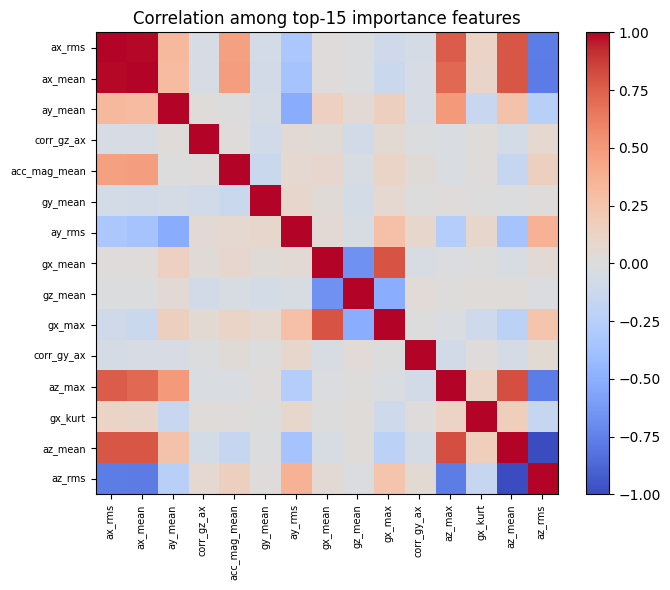

In [6]:
fc = pooled[FEATS].corr().abs()
iu = np.triu(np.ones(fc.shape, bool), 1)
n_redundant = int((fc.values[iu] > 0.95).sum())
print(f"feature pairs with |corr| > 0.95: {n_redundant}")

topk = imp.head(15).index.tolist()
sub = pooled[topk].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(sub, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(topk))); ax.set_xticklabels(topk, rotation=90, fontsize=7)
ax.set_yticks(range(len(topk))); ax.set_yticklabels(topk, fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Correlation among top-15 importance features")
fig.tight_layout(); fig.savefig(FIG / "feature_redundancy_heatmap.png", dpi=150); plt.show()

## 6. Feature-selection experiment (leakage-safe)

Does a compact subset keep most of the signal? We evaluate top-k feature sets under the project's **leave-one-sequence-out** split, fitting the scaler and the importance ranking on the training sequences only (so neither the ranking nor the scaler sees the held-out sequence). We report mean MAE across the three folds — a rough guide for Part D, not the final result.

k
5      0.0105
10     0.0103
20     0.0103
40     0.0103
104    0.0102


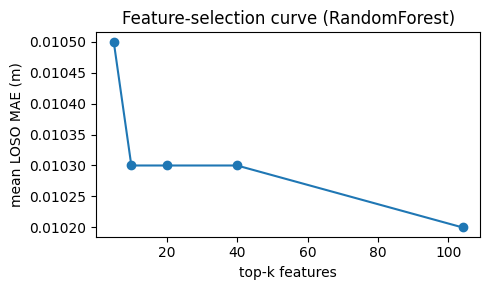

In [7]:
from sklearn.metrics import mean_absolute_error

def loso_mae(feature_subset_from_train):
    maes = []
    for test_seq in sequences:
        train = pd.concat([frames[s] for s in sequences if s != test_seq], ignore_index=True)
        test = frames[test_seq]
        # rank + scale on TRAIN only
        ranker = RandomForestRegressor(n_estimators=200, random_state=seed, n_jobs=-1)
        ranker.fit(train[FEATS], train["err_mag_m"])
        order = pd.Series(ranker.feature_importances_, index=FEATS).sort_values(ascending=False)
        for k in ks:
            cols = order.head(k).index.tolist()
            scaler = fit_scaler(train)  # fit on train only
            tr = apply_scaler(train, scaler); te = apply_scaler(test, scaler)
            m = RandomForestRegressor(n_estimators=200, random_state=seed, n_jobs=-1)
            m.fit(tr[cols], tr["err_mag_m"])
            maes.append((k, test_seq, mean_absolute_error(te["err_mag_m"], m.predict(te[cols]))))
    return pd.DataFrame(maes, columns=["k", "test_seq", "mae"])

ks = [5, 10, 20, 40, len(FEATS)]
res = loso_mae(ks)
summary = res.groupby("k")["mae"].mean().round(4)
print(summary.to_string())

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(summary.index, summary.values, marker="o")
ax.set_xlabel("top-k features"); ax.set_ylabel("mean LOSO MAE (m)")
ax.set_title("Feature-selection curve (RandomForest)")
fig.tight_layout(); fig.savefig(FIG / "feature_selection_curve.png", dpi=150); plt.show()

## What we learned

- **104 features** (60 time-domain + 18 frequency + 26 cross-axis), no NaNs, one row per window.
- All three families surface in the top correlates: accelerometer mean/RMS (time), spectral entropy (frequency), and magnitude/correlation terms (cross-axis).
- The set is redundant by design; a compact top-k subset retains most of the signal (see the selection curve), but the full set is kept for Phase 1 so per-family contributions can be compared.
- **Handoff:** `data/processed/features_<seq>.csv` + `docs/feature_dictionary.md` → Part D. Scaling is left to Part D, fit on each fold's training sequences only.